### Prof. Alfio Ferrara

# Classificare i testi

##  Metodologie informatiche nelle discipline umanistiche
##### A.A. 2026/2027

---

Con la ricerca abbiamo dato un punteggio a ogni documento per una domanda. Ora rovesciamo la prospettiva: dato **un documento**, vogliamo dire a quale **classe** appartiene. Il clima di una città, l'autore di un testo, il genere di un romanzo, il tono di una lettera sono tutti problemi di questo tipo.

Prima definiamo il problema in modo da poterlo risolvere con strumenti molto diversi. Poi costruiamo, con tre parole e due classi, una piccola **rete neurale** e guardiamo tutti i numeri passo passo.

## Che cos'è classificare

Un problema di classificazione ha tre ingredienti: un **documento** $d$, un insieme finito di **classi** $C = \{c_1, \dots, c_k\}$ e il compito di decidere a quale classe appartiene $d$.

Il modo più flessibile di formularlo non è «dammi la classe», ma:

> per ogni documento $d$ e per ogni classe $c$ possibile, calcola un **punteggio** $\text{score}(d, c)$.

La decisione viene dopo, ed è una regola che si applica ai punteggi. La più semplice è scegliere la classe con il punteggio più alto:

$$\hat{c}(d) = \arg\max_{c \in C} \; \text{score}(d, c)$$

Con gli stessi punteggi, cambiando solo la regola, si risolvono problemi diversi: una sola classe (il massimo), nessuna classe se il massimo è troppo basso, più etichette insieme (tutte le classi sopra una soglia), una graduatoria delle classi, un'indicazione di quanto il sistema è incerto (la distanza tra il primo e il secondo punteggio). È la stessa idea della ricerca: lì il punteggio era tra un documento e una query, qui è tra un documento e una classe.

Cominciamo con il classificatore più ingenuo: per ogni clima, una lista di parole che ci aspettiamo di trovare. Il punteggio di una classe è il numero di parole del documento che stanno nella sua lista.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

with open('data/clima_citta.json') as f:
    dataset = json.load(f)

parole_chiave = {
    'tropicale': ['umido', 'umida', 'umidità', 'acquazzoni', 'foresta', 'monsone', 'monsoni', 'temporali', 'tropicale'],
    'desertico': ['deserto', 'torride', 'sabbia', 'dune', 'sahara', 'aridità', 'arido', 'aride', 'pioggia'],
    'mediterraneo': ['miti', 'brezza', 'asciutte', 'asciutta', 'soleggiate', 'secche', 'piovosi', 'mare'],
    'temperato': ['stagioni', 'moderate', 'freddi', 'nebbia', 'distinte', 'regolari', 'nevicate', 'tiepide'],
    'polare': ['gelo', 'gelidi', 'ghiacciato', 'ghiaccio', 'polare', 'artico', 'mezzanotte', 'freddo', 'neve'],
}

def punteggi(testo):
    parole = re.findall(r'\w+', testo.lower())
    return pd.Series({c: sum(p in chiavi for p in parole) for c, chiavi in parole_chiave.items()})

def previsione(testo):
    s = punteggi(testo)
    return 'nessuna' if s.max() == 0 else s.idxmax()

esempi = ['Singapore', 'Mascate', 'Seattle', 'Nuuk', 'Alice Springs']
voci = {v['citta']: v for v in dataset}

tabella = pd.DataFrame({n: punteggi(voci[n]['testo']) for n in esempi}).T
tabella['previsione'] = [previsione(voci[n]['testo']) for n in esempi]
tabella['vero'] = [voci[n]['clima'] for n in esempi]
print(tabella.to_string())

corretti = sum(previsione(v['testo']) == v['clima'] for v in dataset)
print(f'\nclassificate bene: {corretti} su {len(dataset)}')

               tropicale  desertico  mediterraneo  temperato  polare    previsione       vero
Singapore              2          0             0          0       0     tropicale  tropicale
Mascate                0          3             0          0       0     desertico  desertico
Seattle                0          0             3          1       1  mediterraneo  temperato
Nuuk                   0          0             1          0       1  mediterraneo     polare
Alice Springs          0          0             0          0       0       nessuna  desertico

classificate bene: 89 su 100


## Un momento di riflessione

- Quali classi hanno ricevuto il punteggio più alto per Singapore e Mascate? Il motivo è nelle parole del testo?
- Per Seattle e Nuuk il punteggio più alto non è quello giusto. Leggete i testi: quali parole hanno ingannato la lista?
- Alice Springs non ha nessun punto. Che cosa può fare un sistema che dà punteggi, e che non potrebbe fare un sistema che restituisce solo una classe?
- Quando due classi hanno lo stesso punteggio, `idxmax` sceglie la prima. È una buona regola? Come potremmo usare il margine tra primo e secondo?
- Le liste le ha scritte una persona, guardando i testi. Dove si vede la fatica di farlo a mano? Quanto durerebbe con 608 parole e cinque classi?
- In una lista una parola vale 1 e le altre 0. Se potessimo dare a ogni parola un **peso diverso per ogni classe**, anche negativo, che cosa cambierebbe?

## Una rete come trasformazione lineare

L'ultima domanda suggerisce il passo successivo: sostituire le liste con una tabella di **pesi**. Lavoriamo con tre sole parole, *caldo*, *umido*, *neve*, e due classi, *tropicale* e *polare*. Un documento diventa un vettore $x$ di tre numeri: 1 se la parola compare, 0 se non compare.

Per ogni classe la tabella ha un peso per ogni parola, più un numero fisso, il **bias**. Il punteggio è la somma dei pesi delle parole presenti più il bias:

$$\text{score}_c = \sum_i x_i \, W_{ic} + b_c \qquad\text{cioè}\qquad s = xW + b$$

Questa è una **rete neurale** con due strati: tre nodi di ingresso, due nodi di uscita, e tra i due una trasformazione lineare. I pesi qui sono scelti a mano.

In [3]:
parole = ['caldo', 'umido', 'neve']
classi = ['tropicale', 'polare']

W = np.array([[ 2.0, -2.0],
              [ 1.5, -0.5],
              [-2.0,  2.5]])
b = np.array([0.0, 0.0])

pd.DataFrame(W, index=parole, columns=classi)

,tropicale,polare
caldo,2.0,-2.0
umido,1.5,-0.5
neve,-2.0,2.5


In [4]:
x = np.array([1, 1, 0])
print('documento: caldo, umido\n')

for j, classe in enumerate(classi):
    termini = ' + '.join(f'{x[i]}×{W[i, j]:g}' for i in range(len(parole)))
    print(f'{classe:10s} = {termini} + {b[j]:g} = {x @ W[:, j] + b[j]:g}')

print('\ns = xW + b =', x @ W + b)

documento: caldo, umido

tropicale  = 1×2 + 1×1.5 + 0×-2 + 0 = 3.5
polare     = 1×-2 + 1×-0.5 + 0×2.5 + 0 = -2.5

s = xW + b = [ 3.5 -2.5]


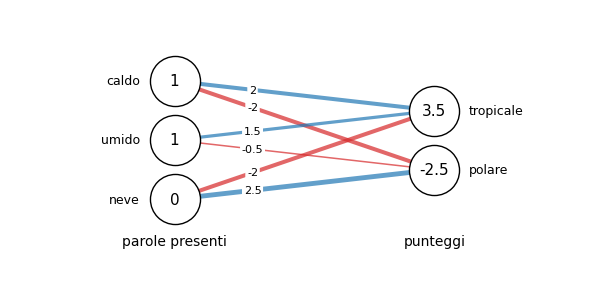

In [5]:
def disegna_rete(valori, pesi, nomi, titoli):
    n = len(valori)
    fig, ax = plt.subplots(figsize=(3.8 * n, 3.4))
    pos = []
    for l, v in enumerate(valori):
        m = len(v)
        pos.append([(3.0 * l, (m - 1) / 2 * 1.4 - i * 1.4) for i in range(m)])
    for l, W_l in enumerate(pesi):
        for i, (x0, y0) in enumerate(pos[l]):
            for j, (x1, y1) in enumerate(pos[l + 1]):
                w = W_l[i, j]
                ax.plot([x0, x1], [y0, y1], color='tab:blue' if w > 0 else 'tab:red', lw=0.5 + 1.2 * abs(w), alpha=0.7, zorder=1)
                ax.text(x0 + 0.3 * (x1 - x0), y0 + 0.3 * (y1 - y0), f'{w:g}', fontsize=8, ha='center', va='center',
                        bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none'), zorder=2)
    for l, v in enumerate(valori):
        for i, (px, py) in enumerate(pos[l]):
            ax.scatter(px, py, s=1300, color='white', edgecolor='black', zorder=3)
            ax.text(px, py, f'{v[i]:g}', ha='center', va='center', fontsize=11, zorder=4)
            lato = -0.4 if l == 0 else 0.4
            ax.text(px + lato, py, nomi[l][i], ha='right' if l == 0 else 'left', va='center', fontsize=9, zorder=4,
                    bbox=dict(boxstyle='round,pad=0.1', fc='white', ec='none'))
        ax.text(3.0 * l, -(max(len(u) for u in valori) - 1) / 2 * 1.4 - 1.1, titoli[l], ha='center', fontsize=10)
    ax.set_xlim(-1.9, 3.0 * (n - 1) + 1.9)
    ax.set_ylim(-3.1, 3.1)
    ax.axis('off')
    plt.show()

disegna_rete([x, x @ W + b], [W], [parole, classi], ['parole presenti', 'punteggi'])

In [6]:
import itertools

combinazioni = np.array(list(itertools.product([0, 1], repeat=3)))
etichette = [' + '.join(p for p, xi in zip(parole, riga) if xi) or '(nessuna)' for riga in combinazioni]

s = combinazioni @ W + b
tabella = pd.DataFrame(s, index=etichette, columns=classi)
tabella['previsione'] = [classi[k] for k in s.argmax(axis=1)]
tabella

,tropicale,polare,previsione
(nessuna),0.0,0.0,tropicale
neve,-2.0,2.5,polare
umido,1.5,-0.5,tropicale
umido + neve,-0.5,2.0,polare
caldo,2.0,-2.0,tropicale
caldo + neve,0.0,0.5,polare
caldo + umido,3.5,-2.5,tropicale
caldo + umido + neve,1.5,0.0,tropicale


## Un momento di riflessione

- Quale parola spinge di più verso *tropicale*? E verso *polare*? Che cosa significa un peso negativo?
- Nel disegno, che cosa rappresentano i colori e lo spessore delle linee?
- Che cosa succede con *caldo + neve*? Il risultato vi sembra ragionevole? Chi decide?
- E con il documento vuoto? Che ruolo ha il bias? Provate a metterne uno diverso da zero per una delle due classi.
- Confrontate questa tabella di pesi con le liste di parole chiave di prima. In che senso una lista è un caso particolare?
- Se il documento contenesse *caldo* due volte, il punteggio raddoppierebbe? Quando è un vantaggio e quando no?
- I punteggi tra le righe sono molto diversi: non sono né percentuali né probabilità. Per scegliere la classe basta confrontarli?

## Quando la somma non basta

Nella trasformazione lineare ogni parola dà il suo contributo **indipendentemente dalle altre**: il punteggio è una somma. Mettiamola alla prova con un compito in cui contano le parole **insieme**.

Due nuove classi: *estremo* se nel testo compare **una sola** tra *caldo* e *neve* (un deserto, una regione polare), *mite* se compaiono **entrambe** (estati calde, inverni nevosi) oppure **nessuna**. La parola *umido* non conta. Sono otto combinazioni possibili e conosciamo la classe giusta di ciascuna. Cerchiamo dei pesi che le classifichino tutte bene: ne proviamo duecentomila, scelti a caso.

                     classe giusta
(nessuna)                     mite
neve                       estremo
umido                         mite
umido + neve               estremo
caldo                      estremo
caldo + neve                  mite
caldo + umido              estremo
caldo + umido + neve          mite

accuratezza raggiunta dai 200000 tentativi:
  0.250: 6666 tentativi
  0.375: 26245 tentativi
  0.500: 133883 tentativi
  0.625: 26500 tentativi
  0.750: 6706 tentativi


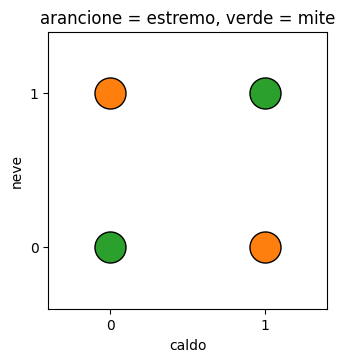

In [7]:
classi2 = ['estremo', 'mite']
atteso = ((combinazioni[:, 0] + combinazioni[:, 2]) == 1).astype(int) ^ 1

compito = pd.DataFrame({'classe giusta': [classi2[k] for k in atteso]}, index=etichette)
print(compito.to_string())

rng = np.random.default_rng(0)
prove = 200_000
W_casuali = rng.normal(size=(prove, 3, 2))
b_casuali = rng.normal(size=(prove, 1, 2))

punteggi_casuali = combinazioni[None, :, :] @ W_casuali + b_casuali
accuratezza = (punteggi_casuali.argmax(axis=2) == atteso[None, :]).mean(axis=1)

valori, conteggi = np.unique(accuratezza, return_counts=True)
print('\naccuratezza raggiunta dai 200000 tentativi:')
for v, c in zip(valori, conteggi):
    print(f'  {v:.3f}: {c} tentativi')

fig, ax = plt.subplots(figsize=(3.6, 3.6))
for caldo, neve in itertools.product([0, 1], repeat=2):
    classe = int(caldo == neve)
    ax.scatter(caldo, neve, s=500, color='tab:orange' if classe == 0 else 'tab:green', edgecolor='black')
ax.set_xlabel('caldo')
ax.set_ylabel('neve')
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xlim(-0.4, 1.4)
ax.set_ylim(-0.4, 1.4)
ax.set_title('arancione = estremo, verde = mite')
plt.show()

## Un momento di riflessione

- Qual è la migliore accuratezza raggiunta tra i duecentomila tentativi? Basterebbe provarne un milione?
- Guardate il disegno: i punti arancioni e verdi si possono separare con **una** linea retta? Che cosa ha a che fare con la somma dei pesi?
- Con *caldo* da solo il punteggio di *estremo* sale. Con *neve* da sola sale. Che cosa dovrebbe succedere con *caldo + neve*? Può succedere con una somma?
- Le parole contano insieme, non una per una. Trovate un esempio di questo fenomeno in un testo vero (una negazione, un'espressione fissa, un nome proprio).
- Che cosa ci serve, allora, oltre a pesi migliori?

## Lo strato nascosto e la funzione di attivazione

Una idea naturale: usare **due trasformazioni di seguito**. Le parole producono prima alcuni valori intermedi, i nodi di uno **strato nascosto**; da questi si calcolano i punteggi delle classi.

$$h = xW_1 + b_1 \qquad s = hW_2 + b_2$$

Proviamo prima così, con pesi qualsiasi, e confrontiamo con una trasformazione sola.

In [8]:
rng = np.random.default_rng(1)
W1 = rng.normal(size=(3, 2))
W2 = rng.normal(size=(2, 2))

due_strati = combinazioni @ W1 @ W2
uno_strato = combinazioni @ (W1 @ W2)

print('stessi punteggi in tutte le otto combinazioni:', np.allclose(due_strati, uno_strato))
print('\nmatrice di un solo strato equivalente W1·W2:')
print((W1 @ W2).round(3))

stessi punteggi in tutte le otto combinazioni: True

matrice di un solo strato equivalente W1·W2:
[[ 0.114  0.442]
 [-0.653 -0.191]
 [-0.323  0.657]]


Due trasformazioni lineari di seguito equivalgono a **una sola** trasformazione lineare (il prodotto delle due matrici, e lo stesso vale con i bias). Lo strato nascosto così com'è non aggiunge nulla: serve qualcosa in mezzo che **non sia lineare**.

La **funzione di attivazione** è una funzione che si applica a ogni valore dello strato nascosto prima di passare al successivo. Una delle più semplici è la **ReLU**:

$$\text{ReLU}(z) = \max(0, z)$$

Lascia passare i valori positivi e azzera i negativi: ogni nodo nascosto «si accende» solo se la sua somma supera zero. Con due nodi nascosti possiamo costruire a mano una rete che risolve il compito di prima: un nodo si accende quando c'è *caldo* ma non *neve*, l'altro quando c'è *neve* ma non *caldo*.

$$h = \text{ReLU}(xW_1 + b_1) \qquad s = hW_2 + b_2$$

In [9]:
def relu(z):
    return np.maximum(0, z)

W1 = np.array([[ 1.0, -1.0],
               [ 0.0,  0.0],
               [-1.0,  1.0]])
b1 = np.array([0.0, 0.0])
W2 = np.array([[1.0, 0.0],
               [1.0, 0.0]])
b2 = np.array([0.0, 0.5])

def rete(X, attivazione=relu):
    z = X @ W1 + b1
    h = attivazione(z)
    return z, h, h @ W2 + b2

z, h, s = rete(combinazioni)
risultato = pd.DataFrame({
    'z1': z[:, 0], 'z2': z[:, 1],
    'h1': h[:, 0], 'h2': h[:, 1],
    'estremo': s[:, 0], 'mite': s[:, 1],
    'previsione': [classi2[k] for k in s.argmax(axis=1)],
    'atteso': [classi2[k] for k in atteso],
}, index=etichette)
print(risultato.to_string())
print('\nconfronto con la rete senza attivazione:')
_, _, s_lineare = rete(combinazioni, attivazione=lambda z: z)
print('  accuratezza con ReLU:   ', (s.argmax(axis=1) == atteso).mean())
print('  accuratezza senza ReLU: ', (s_lineare.argmax(axis=1) == atteso).mean())

                       z1   z2   h1   h2  estremo  mite previsione   atteso
(nessuna)             0.0  0.0  0.0  0.0      0.0   0.5       mite     mite
neve                 -1.0  1.0  0.0  1.0      1.0   0.5    estremo  estremo
umido                 0.0  0.0  0.0  0.0      0.0   0.5       mite     mite
umido + neve         -1.0  1.0  0.0  1.0      1.0   0.5    estremo  estremo
caldo                 1.0 -1.0  1.0  0.0      1.0   0.5    estremo  estremo
caldo + neve          0.0  0.0  0.0  0.0      0.0   0.5       mite     mite
caldo + umido         1.0 -1.0  1.0  0.0      1.0   0.5    estremo  estremo
caldo + umido + neve  0.0  0.0  0.0  0.0      0.0   0.5       mite     mite

confronto con la rete senza attivazione:
  accuratezza con ReLU:    1.0
  accuratezza senza ReLU:  0.5


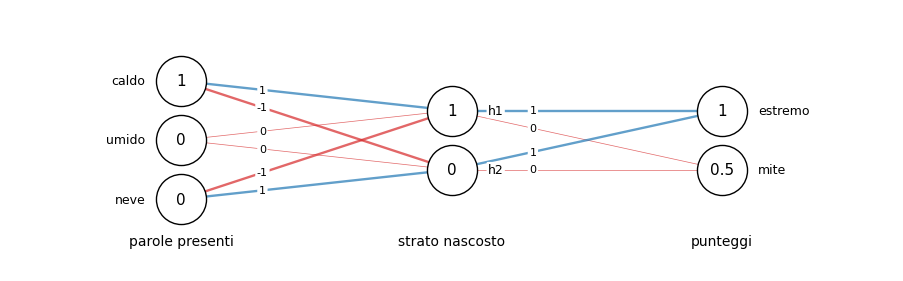

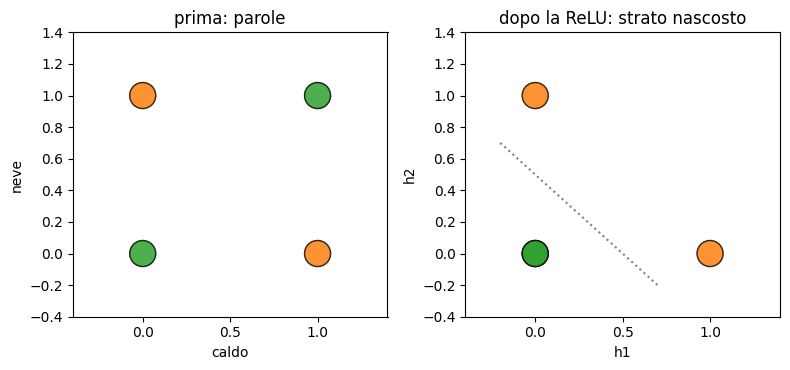

In [10]:
caldo_solo = np.array([1, 0, 0])
z1_, h1_, s1_ = rete(caldo_solo)
disegna_rete([caldo_solo, h1_, s1_], [W1, W2], [parole, ['h1', 'h2'], classi2], ['parole presenti', 'strato nascosto', 'punteggi'])

fig, assi = plt.subplots(1, 2, figsize=(8, 3.8))
colori = ['tab:orange' if a == 0 else 'tab:green' for a in atteso]
for ax, (P, titolo, ex, ey) in zip(assi, [(combinazioni[:, [0, 2]], 'prima: parole', 'caldo', 'neve'), (h, 'dopo la ReLU: strato nascosto', 'h1', 'h2')]):
    ax.scatter(P[:, 0], P[:, 1], s=350, c=colori, edgecolor='black', alpha=0.6)
    ax.set_title(titolo)
    ax.set_xlabel(ex)
    ax.set_ylabel(ey)
    ax.set_xlim(-0.4, 1.4)
    ax.set_ylim(-0.4, 1.4)
assi[1].plot([-0.2, 0.7], [0.7, -0.2], color='gray', linestyle=':')
plt.tight_layout()
plt.show()

## Un momento di riflessione

- Perché due matrici di seguito, senza nulla in mezzo, non aggiungono niente a una sola? Quale proprietà della somma lo garantisce?
- Nella tabella, quando valgono zero *h1* e *h2*? Che cosa ha fatto la ReLU ai valori negativi di *z1* e *z2*?
- Con la ReLU l'accuratezza sale a 1, senza ReLU resta a 0,5. Eppure i pesi sono gli stessi. Che cosa fa la funzione di attivazione?
- Guardate i due pannelli: nel primo i punti arancioni e verdi non si separano con una retta, nel secondo sì. Dove passa la retta? Che cosa è successo ai due punti verdi?
- Perché i nodi nascosti si chiamano così? Li avevamo definiti noi: che cosa rappresenta ciascuno in termini di parole?
- Abbiamo scelto i pesi guardando il problema. Con 608 parole, cinque classi e cento documenti sarebbe ancora possibile?

## I parametri sono la conoscenza della rete

Tutto ciò che la rete «sa» sta nei suoi **parametri**, cioè nei pesi $W$ e nei bias $b$. Con gli stessi parole e la stessa formula $s = xW + b$, parametri diversi producono classificazioni diverse. Lo vediamo con una rete a **uno strato solo**, tre parole e due classi, con una novità: i punteggi vengono trasformati in **probabilità** con la funzione **softmax**.

$$p_c = \frac{e^{s_c}}{\sum_{c'} e^{s_{c'}}}$$

I punteggi diventano numeri positivi che sommano a 1. Per misurare quanto la rete sbaglia ci servono dei documenti di cui conosciamo la classe: sei, riportati sotto. L'**errore** su un documento è $-\ln p$, dove $p$ è la probabilità che la rete assegna alla classe **giusta**: vale 0 se $p = 1$ e cresce al diminuire di $p$. L'errore complessivo (la *loss*) è la media sui sei documenti.

I parametri di partenza sono scelti a caso, senza guardare i documenti.

In [11]:
X_tr = np.array([[1, 1, 0],
                 [1, 0, 0],
                 [0, 1, 0],
                 [0, 0, 1],
                 [0, 1, 1],
                 [1, 0, 1]], dtype=float)
y_tr = np.array([0, 0, 0, 1, 1, 1])
nomi_tr = [' + '.join(p for p, xi in zip(parole, riga) if xi) for riga in X_tr]

def softmax(s):
    e = np.exp(s - s.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

def errori(W, b):
    p = softmax(X_tr @ W + b)
    return -np.log(p[np.arange(len(y_tr)), y_tr])

def perdita(W, b):
    return errori(W, b).mean()

def tabelle(W, b):
    s = X_tr @ W + b
    e = np.exp(s)
    p = softmax(s)
    passi = pd.DataFrame({
        's tropicale': s[:, 0], 's polare': s[:, 1],
        'e^s tropicale': e[:, 0], 'e^s polare': e[:, 1], 'somma': e.sum(axis=1),
        'p tropicale': p[:, 0], 'p polare': p[:, 1],
    }, index=nomi_tr)
    giudizio = pd.DataFrame({
        'classe giusta': [classi[k] for k in y_tr],
        'p giusta': p[np.arange(len(y_tr)), y_tr],
        'errore -ln p': errori(W, b),
    }, index=nomi_tr)
    return passi, giudizio

pesi = np.array([[0.0,  1.0],
                 [0.5,  0.0],
                 [0.0, -0.5]])
bias = np.zeros(2)

print('pesi (righe: parole, colonne: classi)')
print(pd.DataFrame(pesi, index=parole, columns=classi).to_string())

passi, giudizio = tabelle(pesi, bias)
print('\nda punteggi a probabilità')
print(passi.round(3).to_string())
print('\nerrore')
print(giudizio.round(3).to_string())
print(f'\nerrore medio (loss): {perdita(pesi, bias):.3f}')

pesi (righe: parole, colonne: classi)
       tropicale  polare
caldo        0.0     1.0
umido        0.5     0.0
neve         0.0    -0.5

da punteggi a probabilità
               s tropicale  s polare  e^s tropicale  e^s polare  somma  p tropicale  p polare
caldo + umido          0.5       1.0          1.649       2.718  4.367        0.378     0.622
caldo                  0.0       1.0          1.000       2.718  3.718        0.269     0.731
umido                  0.5       0.0          1.649       1.000  2.649        0.622     0.378
neve                   0.0      -0.5          1.000       0.607  1.607        0.622     0.378
umido + neve           0.5      -0.5          1.649       0.607  2.255        0.731     0.269
caldo + neve           0.0       0.5          1.000       1.649  2.649        0.378     0.622

errore
              classe giusta  p giusta  errore -ln p
caldo + umido     tropicale     0.378         0.974
caldo             tropicale     0.269         1.313
umido        

## Un momento di riflessione

- Per *caldo + umido* qual è la classe più probabile secondo la rete? È quella giusta? Seguite i numeri dal punteggio alla probabilità.
- Perché passare per $e^s$ e non dividere direttamente i punteggi per la loro somma? Che cosa succederebbe con un punteggio negativo?
- Che cosa significa che la probabilità della classe giusta è 0,27 e l'errore 1,31? E se fosse 0,99?
- Quali documenti pesano di più nella media? Che cosa vuol dire che l'errore è «molto alto» per un documento solo?
- Con questi parametri quanti documenti su sei sono classificati bene (classe con probabilità maggiore)? L'errore medio e il numero di documenti giusti dicono la stessa cosa?

## Cambiare un parametro

Modifichiamo **un solo** parametro: il peso con cui *caldo* spinge verso *polare*, che passa da 1 a −1. Tutto il resto resta uguale. Guardiamo che cosa succede ai sei documenti.

In [12]:
nuovi_pesi = pesi.copy()
nuovi_pesi[0, 1] = -1.0

print('pesi prima e dopo')
print(pd.concat({'prima': pd.DataFrame(pesi, index=parole, columns=classi),
                 'dopo': pd.DataFrame(nuovi_pesi, index=parole, columns=classi)}, axis=1).to_string())

prima_passi, prima_giud = tabelle(pesi, bias)
dopo_passi, dopo_giud = tabelle(nuovi_pesi, bias)

confronto = pd.DataFrame({
    'classe giusta': prima_giud['classe giusta'],
    'p polare prima': prima_passi['p polare'],
    'p polare dopo': dopo_passi['p polare'],
    'errore prima': prima_giud['errore -ln p'],
    'errore dopo': dopo_giud['errore -ln p'],
})
print()
print(confronto.round(3).to_string())
print(f'\nerrore medio: prima {perdita(pesi, bias):.3f}, dopo {perdita(nuovi_pesi, bias):.3f}')

pesi prima e dopo
          prima             dopo       
      tropicale polare tropicale polare
caldo       0.0    1.0       0.0   -1.0
umido       0.5    0.0       0.5    0.0
neve        0.0   -0.5       0.0   -0.5

              classe giusta  p polare prima  p polare dopo  errore prima  errore dopo
caldo + umido     tropicale           0.622          0.182         0.974        0.201
caldo             tropicale           0.731          0.269         1.313        0.313
umido             tropicale           0.378          0.378         0.474        0.474
neve                 polare           0.378          0.378         0.974        0.974
umido + neve         polare           0.269          0.269         1.313        1.313
caldo + neve         polare           0.622          0.182         0.474        1.701

errore medio: prima 0.920, dopo 0.830


## Un momento di riflessione

- Quali documenti sono cambiati e quali no? Perché proprio quelli?
- Per i documenti con *caldo* la probabilità di *polare* è scesa. Per alcuni è un bene, per altri un male. Quali? Perché?
- L'errore medio è sceso, ma non per tutti i documenti. Un solo parametro serve molti documenti: che cosa comporta quando decidiamo come cambiarlo?
- Se avessimo modificato il peso di *umido* verso *tropicale*, gli stessi documenti sarebbero cambiati? Provate a prevederlo prima di eseguire.
- Quanti valori diversi possiamo dare a quel peso? Come troviamo il migliore, senza provarli tutti?

## L'errore come funzione di un parametro

Il risultato precedente è un punto di una curva. Teniamo fermi tutti i parametri tranne il peso di *caldo* verso *polare* e chiamiamolo $w$. Per ogni valore di $w$ otteniamo un errore medio: la curva di $w$ contro l'errore. Per ogni punto ci interessa anche la **pendenza**: di quanto varia l'errore se muoviamo $w$ di un passo molto piccolo $h$.

$$\text{pendenza}(w) \approx \frac{L(w + h) - L(w)}{h}$$

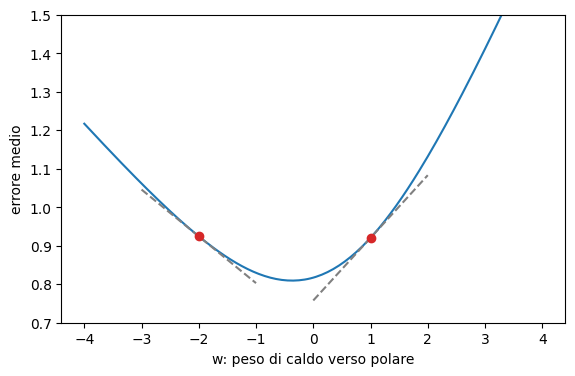

,errore,pendenza
w,,
-3.0,1.062,-0.149
-2.0,0.924,-0.122
-1.0,0.830,-0.061
-0.4,0.809,-0.003
0.0,0.817,0.043
1.0,0.920,0.163
2.0,1.132,0.253
3.0,1.411,0.300


In [13]:
def perdita_con(w):
    p = pesi.copy()
    p[0, 1] = w
    return perdita(p, bias)

def pendenza(w, h=1e-6):
    return (perdita_con(w + h) - perdita_con(w)) / h

valori_w = np.linspace(-4, 4, 161)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(valori_w, [perdita_con(w) for w in valori_w])
for w0 in [-2.0, 1.0]:
    t = np.linspace(w0 - 1, w0 + 1, 2)
    ax.plot(t, perdita_con(w0) + pendenza(w0) * (t - w0), linestyle='--', color='gray')
    ax.scatter(w0, perdita_con(w0), color='tab:red', zorder=3)
ax.set_xlabel('w: peso di caldo verso polare')
ax.set_ylabel('errore medio')
ax.set_ylim(0.7, 1.5)
plt.show()

tab = pd.DataFrame({'errore': [perdita_con(w) for w in [-3, -2, -1, -0.4, 0, 1, 2, 3]],
                    'pendenza': [pendenza(w) for w in [-3, -2, -1, -0.4, 0, 1, 2, 3]]},
                   index=pd.Index([-3, -2, -1, -0.4, 0, 1, 2, 3], name='w'))
tab.round(3)

## Un momento di riflessione

- Dove si trova il punto più basso della curva? Quanto vale l'errore lì?
- Che segno ha la pendenza a sinistra del minimo, e quale a destra? Che cosa vi dice sul verso in cui conviene muovere $w$?
- Che cosa succede alla pendenza vicino al minimo? Perché?
- Il minimo vale circa 0,81 e non è vicino a zero. Una sola manopola, con tutte le altre ferme, può fare una rete buona?
- In due punti con la stessa distanza dal minimo la pendenza ha lo stesso valore assoluto? Che cosa dice la forma della curva?

## Scendere lungo la curva

Se la pendenza dice in quale verso l'errore cresce, per farlo diminuire basta andare nel verso opposto. Facciamo un passo alla volta:

$$w \leftarrow w - \eta \cdot \text{pendenza}(w)$$

Il numero $\eta$ (*learning rate*) decide quanto è lungo il passo rispetto alla pendenza. Questa è la **discesa del gradiente** (*gradient descent*) per un solo parametro. Partiamo da $w = 1$ e proviamo diversi valori di $\eta$.

eta = 3: passo per passo
        w  errore  pendenza
0   1.000   0.920     0.163
1   0.512   0.855     0.105
2   0.196   0.828     0.066
3  -0.003   0.817     0.042
4  -0.129   0.813     0.027
5  -0.211   0.811     0.018
6  -0.264   0.810     0.012
7  -0.299   0.810     0.008
8  -0.322   0.810     0.005
9  -0.338   0.809     0.003
10 -0.348   0.809     0.002

dopo 10 passi
          w  errore
eta                
0.1   0.845   0.897
1.0   0.019   0.818
3.0  -0.348   0.809
10.0 -0.369   0.809
30.0  0.298   0.835


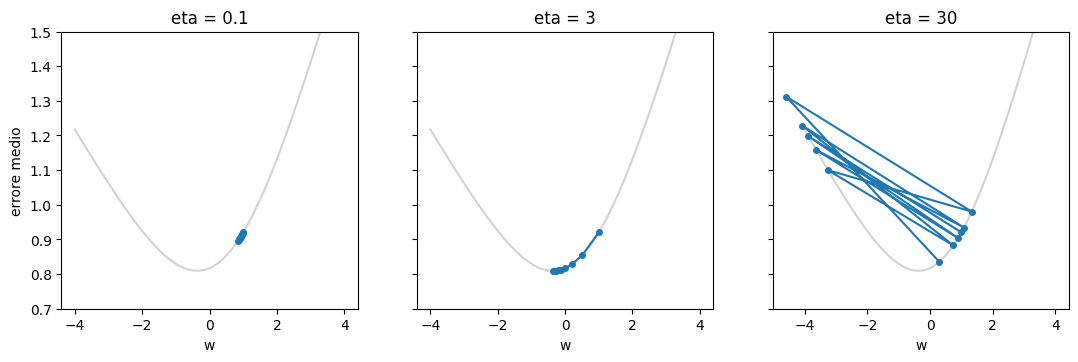

In [14]:
def discesa(eta, passi=10, w0=1.0):
    w = w0
    storia = []
    for _ in range(passi):
        storia.append((w, perdita_con(w), pendenza(w)))
        w = w - eta * pendenza(w)
    storia.append((w, perdita_con(w), pendenza(w)))
    return pd.DataFrame(storia, columns=['w', 'errore', 'pendenza'])

print('eta = 3: passo per passo')
print(discesa(3.0).round(3).to_string())

risultati = {eta: discesa(eta).iloc[-1] for eta in [0.1, 1, 3, 10, 30]}
print('\ndopo 10 passi')
print(pd.DataFrame(risultati, index=['w', 'errore']).T.rename_axis('eta').round(3).to_string())

fig, assi = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, eta in zip(assi, [0.1, 3, 30]):
    d = discesa(eta)
    ax.plot(valori_w, [perdita_con(w) for w in valori_w], color='lightgray')
    ax.plot(d['w'], d['errore'], marker='o', markersize=4)
    ax.set_title(f'eta = {eta:g}')
    ax.set_xlabel('w')
    ax.set_ylim(0.7, 1.5)
assi[0].set_ylabel('errore medio')
plt.show()

## Un momento di riflessione

- Nella tabella con $\eta = 3$, che cosa succede a $w$, all'errore e alla pendenza passo dopo passo? Perché i passi diventano più corti pur con lo stesso $\eta$?
- Con $\eta = 0{,}1$ l'errore scende, ma dopo dieci passi siamo ancora lontani. Con $\eta = 30$ che cosa succede? Guardate i tre grafici.
- Esiste un valore di $\eta$ giusto per tutti i problemi? Come lo si sceglie?
- Quando fermiamo la discesa? Quale numero guardereste?
- La discesa trova il minimo della curva di *un* parametro, ma si ferma a 0,81. Che cosa manca?

## Tutti i parametri insieme

La rete ha otto parametri: sei pesi e due bias. Per ognuno possiamo calcolare la pendenza dell'errore, tenendo fermi gli altri. L'insieme delle otto pendenze è il **gradiente**. Poi spostiamo **tutti** i parametri insieme, ciascuno nel verso opposto alla propria pendenza, e ripetiamo.

gradiente nel punto di partenza
caldo→tropicale   -0.163
caldo→polare       0.163
umido→tropicale   -0.045
umido→polare       0.045
neve→tropicale     0.289
neve→polare       -0.289
bias tropicale     0.000
bias polare        0.000



errore medio durante la discesa
  passo   0: 0.920
  passo   1: 0.813
  passo   2: 0.722
  passo   5: 0.523
  passo  10: 0.345
  passo  20: 0.199
  passo  50: 0.087
  passo 100: 0.045
  passo 200: 0.023


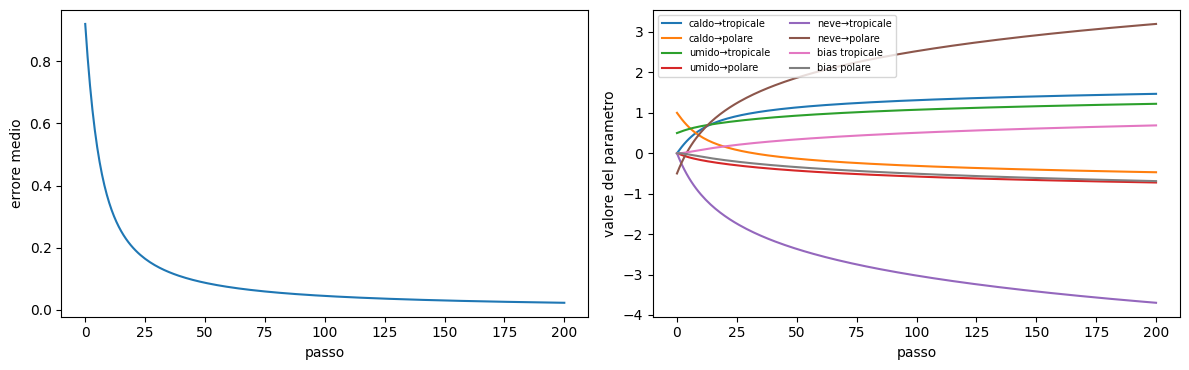

In [15]:
def impacchetta(W, b):
    return np.concatenate([W.ravel(), b])

def spacchetta(theta):
    return theta[:6].reshape(3, 2), theta[6:]

def perdita_theta(theta):
    return perdita(*spacchetta(theta))

def gradiente(theta, h=1e-6):
    g = np.zeros_like(theta)
    base = perdita_theta(theta)
    for i in range(len(theta)):
        t = theta.copy()
        t[i] += h
        g[i] = (perdita_theta(t) - base) / h
    return g

nomi_parametri = [f'{p}→{c}' for p in parole for c in classi] + [f'bias {c}' for c in classi]

theta = impacchetta(pesi, bias)
print('gradiente nel punto di partenza')
print(pd.Series(gradiente(theta), index=nomi_parametri).round(3).to_string())

eta = 0.5
storia = [theta.copy()]
for _ in range(200):
    theta = theta - eta * gradiente(theta)
    storia.append(theta.copy())
storia = np.array(storia)
errori_storia = [perdita_theta(t) for t in storia]

print('\nerrore medio durante la discesa')
for passo in [0, 1, 2, 5, 10, 20, 50, 100, 200]:
    print(f'  passo {passo:3d}: {errori_storia[passo]:.3f}')

fig, assi = plt.subplots(1, 2, figsize=(12, 3.8))
assi[0].plot(errori_storia)
assi[0].set_xlabel('passo')
assi[0].set_ylabel('errore medio')
assi[1].plot(storia)
assi[1].legend(nomi_parametri, fontsize=7, ncol=2)
assi[1].set_xlabel('passo')
assi[1].set_ylabel('valore del parametro')
plt.tight_layout()
plt.show()

In [16]:
W_fin, b_fin = spacchetta(storia[-1])

print('pesi: partenza e arrivo')
print(pd.concat({'partenza': pd.DataFrame(pesi, index=parole, columns=classi),
                 'arrivo': pd.DataFrame(W_fin, index=parole, columns=classi)}, axis=1).round(2).to_string())
print('bias: partenza', bias, 'arrivo', b_fin.round(2))

passi_fin, giud_fin = tabelle(W_fin, b_fin)
print('\nprobabilità e errore alla fine')
print(pd.concat([passi_fin[['p tropicale', 'p polare']], giud_fin], axis=1).round(3).to_string())
print(f'\nerrore medio: {perdita(W_fin, b_fin):.3f}')
print('documenti classificati bene:', int((softmax(X_tr @ W_fin + b_fin).argmax(axis=1) == y_tr).sum()), 'su', len(y_tr))

pesi: partenza e arrivo
       partenza           arrivo       
      tropicale polare tropicale polare
caldo       0.0    1.0      1.47  -0.47
umido       0.5    0.0      1.22  -0.72
neve        0.0   -0.5     -3.70   3.20
bias: partenza [0. 0.] arrivo [ 0.69 -0.69]

probabilità e errore alla fine
               p tropicale  p polare classe giusta  p giusta  errore -ln p
caldo + umido        0.995     0.005     tropicale     0.995         0.005
caldo                0.965     0.035     tropicale     0.965         0.036
umido                0.965     0.035     tropicale     0.965         0.035
neve                 0.004     0.996        polare     0.996         0.004
umido + neve         0.027     0.973        polare     0.973         0.028
caldo + neve         0.027     0.973        polare     0.973         0.028

errore medio: 0.023
documenti classificati bene: 6 su 6


## Un momento di riflessione

- Nel grafico a sinistra l'errore scende continuamente? Si ferma? Dove vedete che la discesa rallenta?
- Quali parametri si muovono di più nel grafico a destra? Quali di meno? Corrisponde alle pendenze iniziali?
- Confrontate i pesi di partenza e quelli di arrivo con le intuizioni di prima: *neve* verso *polare*, *umido* verso *tropicale*. La rete ha imparato qualcosa di sensato? Chi glielo ha detto?
- Nessuno ha scelto questi pesi: li ha prodotti la regola «sposta ogni parametro contro la sua pendenza». Che ruolo hanno avuto i sei documenti di esempio?
- Per calcolare il gradiente abbiamo ripetuto il calcolo dell'errore una volta per ogni parametro. Con otto parametri va bene. Quante volte servirebbe con 608 parole e cinque classi? E con milioni di parametri?
- Abbiamo imparato sui sei documenti. Come sappiamo se funzionerà su documenti nuovi?

## Dati veri: il clima delle città

Usiamo di nuovo i cento testi sulle città. Ogni testo ha già un'etichetta, il suo **clima**: cinque classi da venti documenti. È il compito che la lista di parole chiave risolveva con 89 documenti su 100: ora lo affidiamo a una rete che impara i pesi dagli esempi.

Gli ingressi sono i vettori **tf-idf** dei documenti, normalizzati alla lunghezza 1, come nei notebook precedenti. C'è però una precauzione. Se valutassimo la rete sugli stessi documenti su cui impara, non sapremmo se ha imparato a classificare o a ricordare quei testi. Dividiamo quindi i documenti in due gruppi: **addestramento** (70) per far scendere l'errore e **verifica** (30, sei per classe) che la rete non vede mai durante l'apprendimento. Vocabolario e idf si calcolano solo sull'addestramento: le parole che compaiono soltanto nei testi di verifica non hanno una colonna, come le parole fuori vocabolario di una query.

In [17]:
classi_clima = ['tropicale', 'desertico', 'mediterraneo', 'temperato', 'polare']
testi_tok = [re.findall(r'[^\W\d_]+', v['testo'].lower()) for v in dataset]
nomi_citta = np.array([v['citta'] for v in dataset])
y_tutti = np.array([classi_clima.index(v['clima']) for v in dataset])

def prepara_dati(seed=0, per_classe_test=6):
    rng = np.random.default_rng(seed)
    test = np.zeros(len(dataset), dtype=bool)
    for c in range(len(classi_clima)):
        test[rng.permutation(np.flatnonzero(y_tutti == c))[:per_classe_test]] = True
    i_add, i_ver = np.flatnonzero(~test), np.flatnonzero(test)

    vocab = sorted({p for i in i_add for p in testi_tok[i]})
    posizione = {p: j for j, p in enumerate(vocab)}
    conteggi = np.zeros((len(dataset), len(vocab)))
    for i, parole_doc in enumerate(testi_tok):
        for p in parole_doc:
            if p in posizione:
                conteggi[i, posizione[p]] += 1

    idf_add = np.log(len(i_add) / (conteggi[i_add] > 0).sum(axis=0))
    tfidf_doc = conteggi / np.maximum(conteggi.sum(axis=1, keepdims=True), 1) * idf_add
    tfidf_doc /= np.maximum(np.linalg.norm(tfidf_doc, axis=1, keepdims=True), 1e-12)
    return {'Xa': tfidf_doc[i_add], 'ya': y_tutti[i_add], 'Xv': tfidf_doc[i_ver], 'yv': y_tutti[i_ver],
            'nomi_v': nomi_citta[i_ver], 'vocabolario': vocab}

dati = prepara_dati(seed=0)
print('parole nel vocabolario:', len(dati['vocabolario']))
print('addestramento:', dati['Xa'].shape, '| verifica:', dati['Xv'].shape)
print(pd.DataFrame({'addestramento': np.bincount(dati['ya'], minlength=5), 'verifica': np.bincount(dati['yv'], minlength=5)}, index=classi_clima).T.to_string())

parole nel vocabolario: 493
addestramento: (70, 493) | verifica: (30, 493)
               tropicale  desertico  mediterraneo  temperato  polare
addestramento         14         14            14         14      14
verifica               6          6             6          6       6


## Un momento di riflessione

- Quante colonne ha ora la matrice, rispetto alle tre parole dell'esempio? Quanti parametri avrà uno strato che va da questo vocabolario a cinque classi?
- Perché le classi sono bilanciate sia nell'addestramento sia nella verifica? Che cosa potrebbe andare storto in una divisione completamente casuale?
- Perché idf e vocabolario non si calcolano su tutti i cento documenti? Che cosa vorrebbe dire «aver visto» la verifica?
- Trenta documenti di verifica sono molti o pochi? Quanto pesa un singolo documento sull'accuratezza?

## Due reti con uno strato nascosto

La rete ha **uno strato nascosto** di 8 nodi: dal vocabolario agli 8 nodi, poi dagli 8 nodi alle 5 classi, con la softmax in uscita.

$$h = \varphi(xW_1 + b_1) \qquad s = hW_2 + b_2 \qquad p = \text{softmax}(s)$$

Costruiamo due versioni identiche in tutto, tranne la funzione di attivazione $\varphi$: nella prima non fa nulla ($\varphi(z) = z$), nella seconda è la ReLU. Partono dagli stessi parametri casuali.

Il gradiente non lo calcoliamo più provando un parametro alla volta, che con migliaia di parametri sarebbe lentissimo. Si può ricavare con poche righe, partendo dall'uscita e tornando indietro strato per strato (**backpropagation**). Con $n$ documenti, $Y$ le classi giuste in forma di vettori con un solo 1, e $P$ le probabilità:

$$\frac{\partial L}{\partial s} = \frac{P - Y}{n} \qquad \frac{\partial L}{\partial W_2} = h^\top \frac{\partial L}{\partial s} \qquad \frac{\partial L}{\partial z} = \left(\frac{\partial L}{\partial s} W_2^\top\right) \odot \varphi'(z) \qquad \frac{\partial L}{\partial W_1} = x^\top \frac{\partial L}{\partial z}$$

Prima di fidarci verifichiamo alcune di queste pendenze con il metodo numerico di prima.

In [18]:
def identita(z):
    return z

attivazioni = {
    'senza attivazione': (identita, lambda z: np.ones_like(z)),
    'ReLU': (relu, lambda z: (z > 0).astype(float)),
}

def inizializza(n_ingressi, n_nascosti=8, n_classi=5, seed=0):
    rng = np.random.default_rng(seed)
    return {'W1': rng.normal(scale=0.1, size=(n_ingressi, n_nascosti)), 'b1': np.zeros(n_nascosti),
            'W2': rng.normal(scale=0.1, size=(n_nascosti, n_classi)), 'b2': np.zeros(n_classi)}

def avanti(par, X, attivazione):
    z = X @ par['W1'] + par['b1']
    h = attivazioni[attivazione][0](z)
    return z, h, softmax(h @ par['W2'] + par['b2'])

def perdita_rete(par, X, y, attivazione):
    p = avanti(par, X, attivazione)[2]
    return -np.log(p[np.arange(len(y)), y] + 1e-12).mean()

def gradienti(par, X, y, attivazione):
    z, h, p = avanti(par, X, attivazione)
    ds = (p - np.eye(p.shape[1])[y]) / len(y)
    dz = (ds @ par['W2'].T) * attivazioni[attivazione][1](z)
    return {'W1': X.T @ dz, 'b1': dz.sum(axis=0), 'W2': h.T @ ds, 'b2': ds.sum(axis=0)}

par_prova = inizializza(dati['Xa'].shape[1])
g = gradienti(par_prova, dati['Xa'], dati['ya'], 'ReLU')
righe = []
parola_forte = dati['Xa'].mean(axis=0).argmax()
for nome, indice in [('W1', (parola_forte, 2)), ('W1', (parola_forte, 5)), ('W2', (0, 1)), ('W2', (4, 3)), ('b2', (2,))]:
    h_ = 1e-6
    base = perdita_rete(par_prova, dati['Xa'], dati['ya'], 'ReLU')
    par_prova[nome][indice] += h_
    numerico = (perdita_rete(par_prova, dati['Xa'], dati['ya'], 'ReLU') - base) / h_
    par_prova[nome][indice] -= h_
    righe.append((f'{nome}{list(indice)}', g[nome][indice], numerico))
print('parola scelta per W1:', dati['vocabolario'][parola_forte])
pd.DataFrame(righe, columns=['parametro', 'backpropagation', 'numerico']).set_index('parametro').round(7)

parola scelta per W1: è


,backpropagation,numerico
parametro,,
"W1[492, 2]",-0.000308,-0.000308
"W1[492, 5]",0.000163,0.000163
"W2[0, 1]",-0.001092,-0.001092
"W2[4, 3]",0.002981,0.002981
b2[2],0.002442,0.002442


## Un momento di riflessione

- Le due colonne coincidono? Che cosa ci dice sul fatto di poter usare la formula al posto del metodo numerico?
- Quanti parametri ha la rete? Quante volte avremmo dovuto ricalcolare l'errore con il metodo numerico per avere un solo gradiente?
- Nella formula compare $\varphi'(z)$. Che valore ha per la rete senza attivazione? E per la ReLU, quando $z$ è negativo?
- Con la ReLU, un nodo nascosto «spento» (valore zero) su un documento contribuisce al gradiente di quel documento? Che conseguenza ha?

## Prima del training

Creiamo le due reti con gli stessi parametri casuali e guardiamo come classificano i **trenta documenti di verifica**. Per ogni classe contiamo come la rete ha classificato i documenti: righe = classe vera, colonne = classe prevista. È la matrice di confusione dei notebook precedenti, estesa a cinque classi: i documenti classificati bene stanno sulla diagonale.

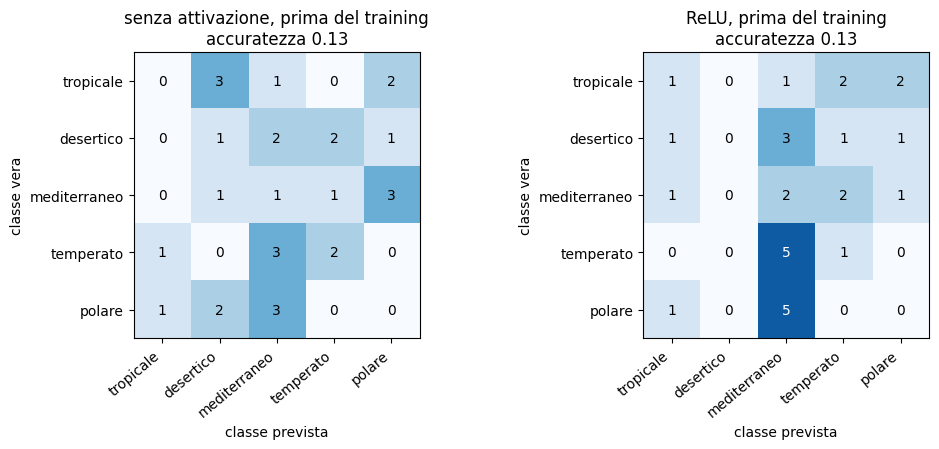

In [19]:
def confusione_classi(y_vero, y_prev):
    M = np.zeros((len(classi_clima), len(classi_clima)), dtype=int)
    np.add.at(M, (y_vero, y_prev), 1)
    return M

def disegna_confusioni(matrici):
    righe = (len(matrici) + 1) // 2
    colonne = min(len(matrici), 2)
    fig, assi = plt.subplots(righe, colonne, figsize=(5.2 * colonne, 4.6 * righe))
    for ax, (titolo, M) in zip(np.atleast_1d(assi).ravel(), matrici.items()):
        ax.imshow(M, cmap='Blues', vmin=0, vmax=6)
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                ax.text(j, i, M[i, j], ha='center', va='center', color='white' if M[i, j] > 3 else 'black')
        ax.set_xticks(range(len(classi_clima)), classi_clima, rotation=40, ha='right')
        ax.set_yticks(range(len(classi_clima)), classi_clima)
        ax.set_xlabel('classe prevista')
        ax.set_ylabel('classe vera')
        ax.set_title(f'{titolo}\naccuratezza {np.trace(M) / M.sum():.2f}')
    plt.tight_layout()
    plt.show()

parametri = {nome: inizializza(dati['Xa'].shape[1], seed=0) for nome in attivazioni}
matrici_prima = {}
for nome in attivazioni:
    previsione = avanti(parametri[nome], dati['Xv'], nome)[2].argmax(axis=1)
    matrici_prima[f'{nome}, prima del training'] = confusione_classi(dati['yv'], previsione)
disegna_confusioni(matrici_prima)

## Un momento di riflessione

- Le due reti partono dagli stessi parametri: i risultati sono uguali o diversi? Perché?
- La rete non ha mai visto un esempio. Le previsioni sono distribuite tra le classi o concentrate? Da che cosa dipende?
- Quale accuratezza ci aspetteremmo da una scelta completamente casuale tra cinque classi? Le matrici sono vicine a quel valore?
- Che cosa c'è nelle colonne di una matrice in cui quasi tutte le previsioni cadono in una sola classe?

## Il training

Ripetiamo ciò che abbiamo fatto con otto parametri: calcolare il gradiente dell'errore sui documenti di addestramento e spostare tutti i parametri nel verso opposto, per 300 passi con $\eta = 1$. A ogni passo registriamo errore e accuratezza **sia sull'addestramento sia sulla verifica**, ma solo l'addestramento determina i parametri.

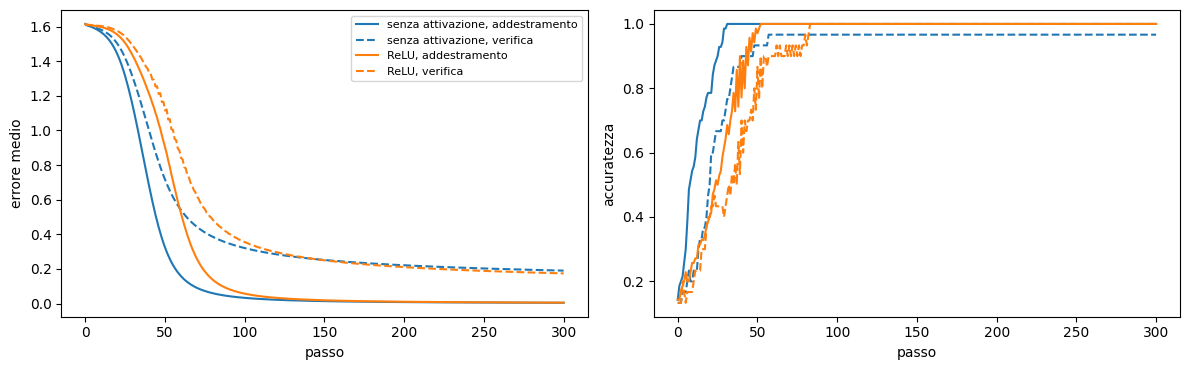

                      senza attivazione   ReLU
0   errore add.                   1.616  1.614
    errore ver.                   1.610  1.612
    accuratezza add.              0.143  0.143
    accuratezza ver.              0.133  0.133
50  errore add.                   0.324  0.902
    errore ver.                   0.716  1.115
    accuratezza add.              1.000  0.971
    accuratezza ver.              0.933  0.867
100 errore add.                   0.033  0.057
    errore ver.                   0.320  0.355
    accuratezza add.              1.000  1.000
    accuratezza ver.              0.967  1.000
300 errore add.                   0.004  0.005
    errore ver.                   0.190  0.174
    accuratezza add.              1.000  1.000
    accuratezza ver.              0.967  1.000


In [20]:
def addestra(par, dati, attivazione, eta=1.0, passi=300):
    par = {k: v.copy() for k, v in par.items()}
    storia = []
    for _ in range(passi + 1):
        storia.append({
            'errore add.': perdita_rete(par, dati['Xa'], dati['ya'], attivazione),
            'errore ver.': perdita_rete(par, dati['Xv'], dati['yv'], attivazione),
            'accuratezza add.': (avanti(par, dati['Xa'], attivazione)[2].argmax(axis=1) == dati['ya']).mean(),
            'accuratezza ver.': (avanti(par, dati['Xv'], attivazione)[2].argmax(axis=1) == dati['yv']).mean(),
        })
        g = gradienti(par, dati['Xa'], dati['ya'], attivazione)
        for k in par:
            par[k] -= eta * g[k]
    return par, pd.DataFrame(storia)

addestrati, storie = {}, {}
for nome in attivazioni:
    addestrati[nome], storie[nome] = addestra(parametri[nome], dati, nome)

fig, assi = plt.subplots(1, 2, figsize=(12, 3.8))
for nome, colore in zip(attivazioni, ['tab:blue', 'tab:orange']):
    assi[0].plot(storie[nome]['errore add.'], color=colore, label=f'{nome}, addestramento')
    assi[0].plot(storie[nome]['errore ver.'], color=colore, linestyle='--', label=f'{nome}, verifica')
    assi[1].plot(storie[nome]['accuratezza add.'], color=colore, label=f'{nome}, addestramento')
    assi[1].plot(storie[nome]['accuratezza ver.'], color=colore, linestyle='--', label=f'{nome}, verifica')
assi[0].set_ylabel('errore medio')
assi[1].set_ylabel('accuratezza')
for ax in assi:
    ax.set_xlabel('passo')
assi[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(pd.DataFrame({nome: s.iloc[[0, 50, 100, 300]].stack() for nome, s in storie.items()}).round(3).to_string())

## Un momento di riflessione

- Quale rete impara più in fretta nei primi passi? Quando le due curve di errore si avvicinano?
- L'errore sull'addestramento scende più dell'errore sulla verifica. Perché? Che cosa succederebbe se continuassimo per altri mille passi?
- L'accuratezza sull'addestramento arriva presto a 1. Possiamo fermarci lì? Quale curva guardereste per decidere quando smettere?
- Le due reti usano gli stessi dati, gli stessi parametri iniziali e lo stesso $\eta$. Che cosa spiega le differenze, se ci sono?

## Dopo il training

Rifacciamo le matrici di confusione sui documenti di verifica, con i parametri appresi, e le mettiamo accanto a quelle di prima. Poi leggiamo i documenti sbagliati.

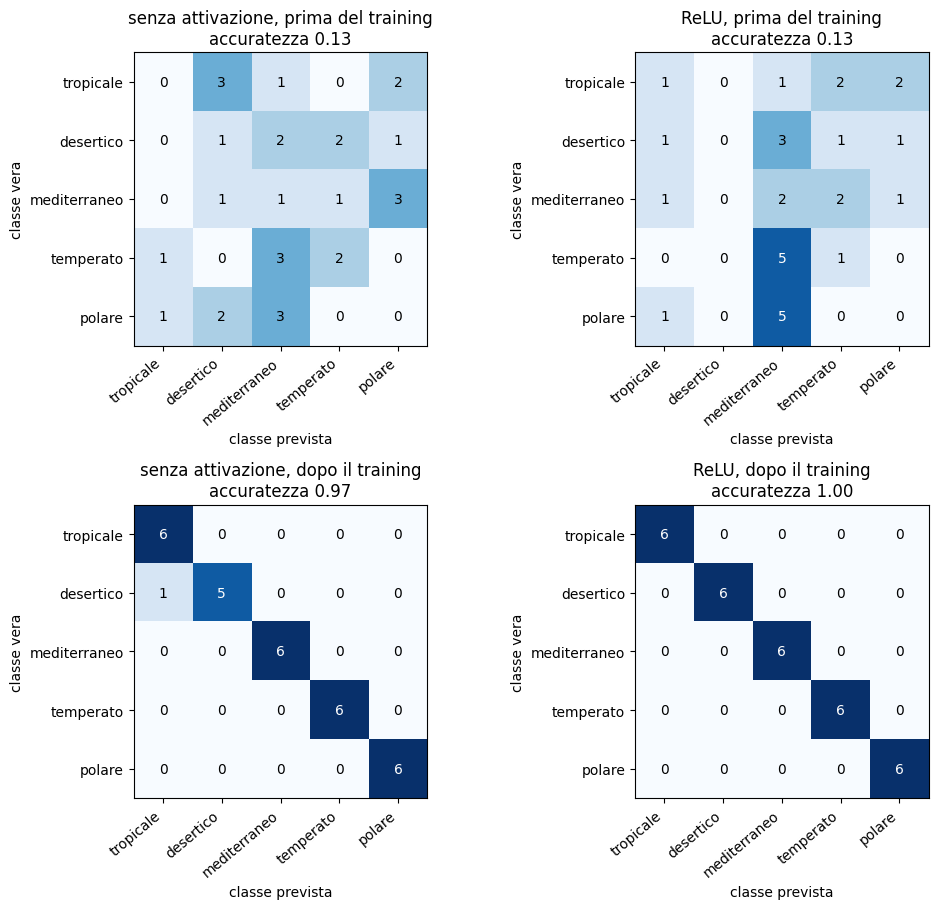

senza attivazione: 1 documenti sbagliati su 30
  Alice Springs: vero desertico, previsto tropicale
ReLU: 0 documenti sbagliati su 30


In [21]:
matrici_dopo = {}
previsioni_dopo = {}
for nome in attivazioni:
    previsioni_dopo[nome] = avanti(addestrati[nome], dati['Xv'], nome)[2].argmax(axis=1)
    matrici_dopo[f'{nome}, dopo il training'] = confusione_classi(dati['yv'], previsioni_dopo[nome])

disegna_confusioni({**{k: matrici_prima[k] for k in list(matrici_prima)}, **matrici_dopo})

for nome in attivazioni:
    sbagliati = np.flatnonzero(previsioni_dopo[nome] != dati['yv'])
    print(f'{nome}: {len(sbagliati)} documenti sbagliati su {len(dati["yv"])}')
    for i in sbagliati:
        print(f'  {dati["nomi_v"][i]}: vero {classi_clima[dati["yv"][i]]}, previsto {classi_clima[previsioni_dopo[nome][i]]}')

## Un momento di riflessione

- Dove stanno ora i documenti nelle matrici? Quale confronto tra «prima» e «dopo» è il più eloquente?
- Quali classi vengono confuse tra loro? Leggete i testi dei documenti sbagliati: l'errore è comprensibile?
- La rete con la ReLU e quella senza fanno gli stessi errori? Una differenza di un documento su trenta è una prova che una funziona meglio dell'altra?
- Confrontate con la lista di parole chiave a mano di inizio notebook (89 su 100, valutata anche sugli stessi testi con cui è stata scritta). Perché il confronto non è del tutto equo?

## Una sola divisione non basta

L'esito dipende da come abbiamo diviso i documenti e da come sono partiti i parametri. Ripetiamo tutto dieci volte, con divisioni e parametri iniziali diversi, e guardiamo l'accuratezza sulla verifica.

In [22]:
risultati = {nome: [] for nome in attivazioni}
for seed in range(10):
    d = prepara_dati(seed=seed)
    for nome in attivazioni:
        par = inizializza(d['Xa'].shape[1], seed=seed)
        par, storia = addestra(par, d, nome)
        risultati[nome].append(storia['accuratezza ver.'].iloc[-1])

tabella = pd.DataFrame(risultati, index=[f'divisione {s}' for s in range(10)])
print(tabella.round(2).to_string())
print()
print(pd.DataFrame({'media': tabella.mean(), 'deviazione standard': tabella.std()}).round(3).to_string())

             senza attivazione  ReLU
divisione 0               0.97  1.00
divisione 1               0.90  0.97
divisione 2               0.90  0.90
divisione 3               1.00  1.00
divisione 4               1.00  1.00
divisione 5               0.97  0.93
divisione 6               0.90  0.87
divisione 7               0.90  0.90
divisione 8               0.97  0.97
divisione 9               0.97  1.00

                   media  deviazione standard
senza attivazione  0.947                0.042
ReLU               0.953                0.050


## Un momento di riflessione

- Le due reti sono diverse in modo sistematico, o la differenza cambia da una divisione all'altra?
- Ci aspettavamo una differenza grande tra la rete con la ReLU e quella senza? Pensate alla sezione in cui l'attivazione risolveva il compito caldo/neve. Che cosa ha di diverso il problema dei climi?
- Se i due modelli sono equivalenti qui, quale scegliereste? Quale parametro in più bisogna addestrare in uno dei due?
- La variazione tra una divisione e l'altra è confrontabile con la differenza tra le due reti? Che cosa dice sull'affidabilità di una sola misura?
- Cosa può fare una rete che la lista di parole chiave non può fare? Cosa può fare la lista che la rete non può?

## Cosa abbiamo visto

1. **Classificare** significa calcolare un punteggio per ogni classe. La decisione (il massimo, una soglia, più etichette, «non so») è una regola applicata dopo.
2. Una **trasformazione lineare** $s = xW + b$ dà il punteggio di ogni classe come somma dei pesi delle parole presenti. Una lista di parole chiave ne è un caso particolare.
3. Una somma non può rappresentare **interazioni** tra parole: il compito caldo/neve non si risolve con nessuna scelta di pesi.
4. Due strati lineari di seguito equivalgono a uno solo. Una **funzione di attivazione** non lineare tra i due (qui la ReLU) rende lo strato nascosto utile.
5. La **conoscenza** della rete sta nei suoi **parametri**: cambiarne uno cambia le probabilità di più documenti, in modo diverso per ciascuno.
6. La **softmax** trasforma i punteggi in probabilità e l'**errore** $-\ln p$ misura quanto la rete sbaglia sulla classe giusta. La media sugli esempi è un solo numero da far diminuire.
7. L'errore è una **funzione dei parametri**. La **pendenza** dice in quale verso aumenta: muovendo il parametro nel verso opposto l'errore scende. Ripetere il passo è la **discesa del gradiente**. Il learning rate decide la lunghezza del passo.
8. Con migliaia di parametri il gradiente si calcola con la **backpropagation**, partendo dall'uscita, e coincide con quello numerico.
9. Su dati veri (tf-idf dei cento testi, cinque climi) si separano documenti di **addestramento** e di **verifica**. La matrice di confusione sui documenti di verifica passa da previsioni quasi casuali a una diagonale piena.
10. Una singola divisione è una misura rumorosa: per confrontare due modelli servono più prove. Su questo problema l'attivazione non cambia molto, perché i climi si separano già con una somma di pesi.

Restano aperte alcune domande su come procedere:

- **Che cosa ha imparato la rete?** Possiamo leggere i pesi: quali parole spingono verso ciascuna classe? Corrispondono alle liste scritte a mano?
- **Quanto possiamo fidarci?** Pochi documenti e vocabolario piccolo: che cosa succede con testi di un altro tipo, con parole mai viste?
- **Quando serve davvero la non linearità?** Servono compiti in cui le parole contano insieme, e rappresentazioni che catturino il significato, non solo le parole.
- **Dalla rete ai modelli di linguaggio.** Quali ingredienti vengono aggiunti per passare da questa rete a un Transformer?